<a href="https://colab.research.google.com/github/Ignacio3000/TP_Filtros_Activos/blob/main/TP_sintesis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

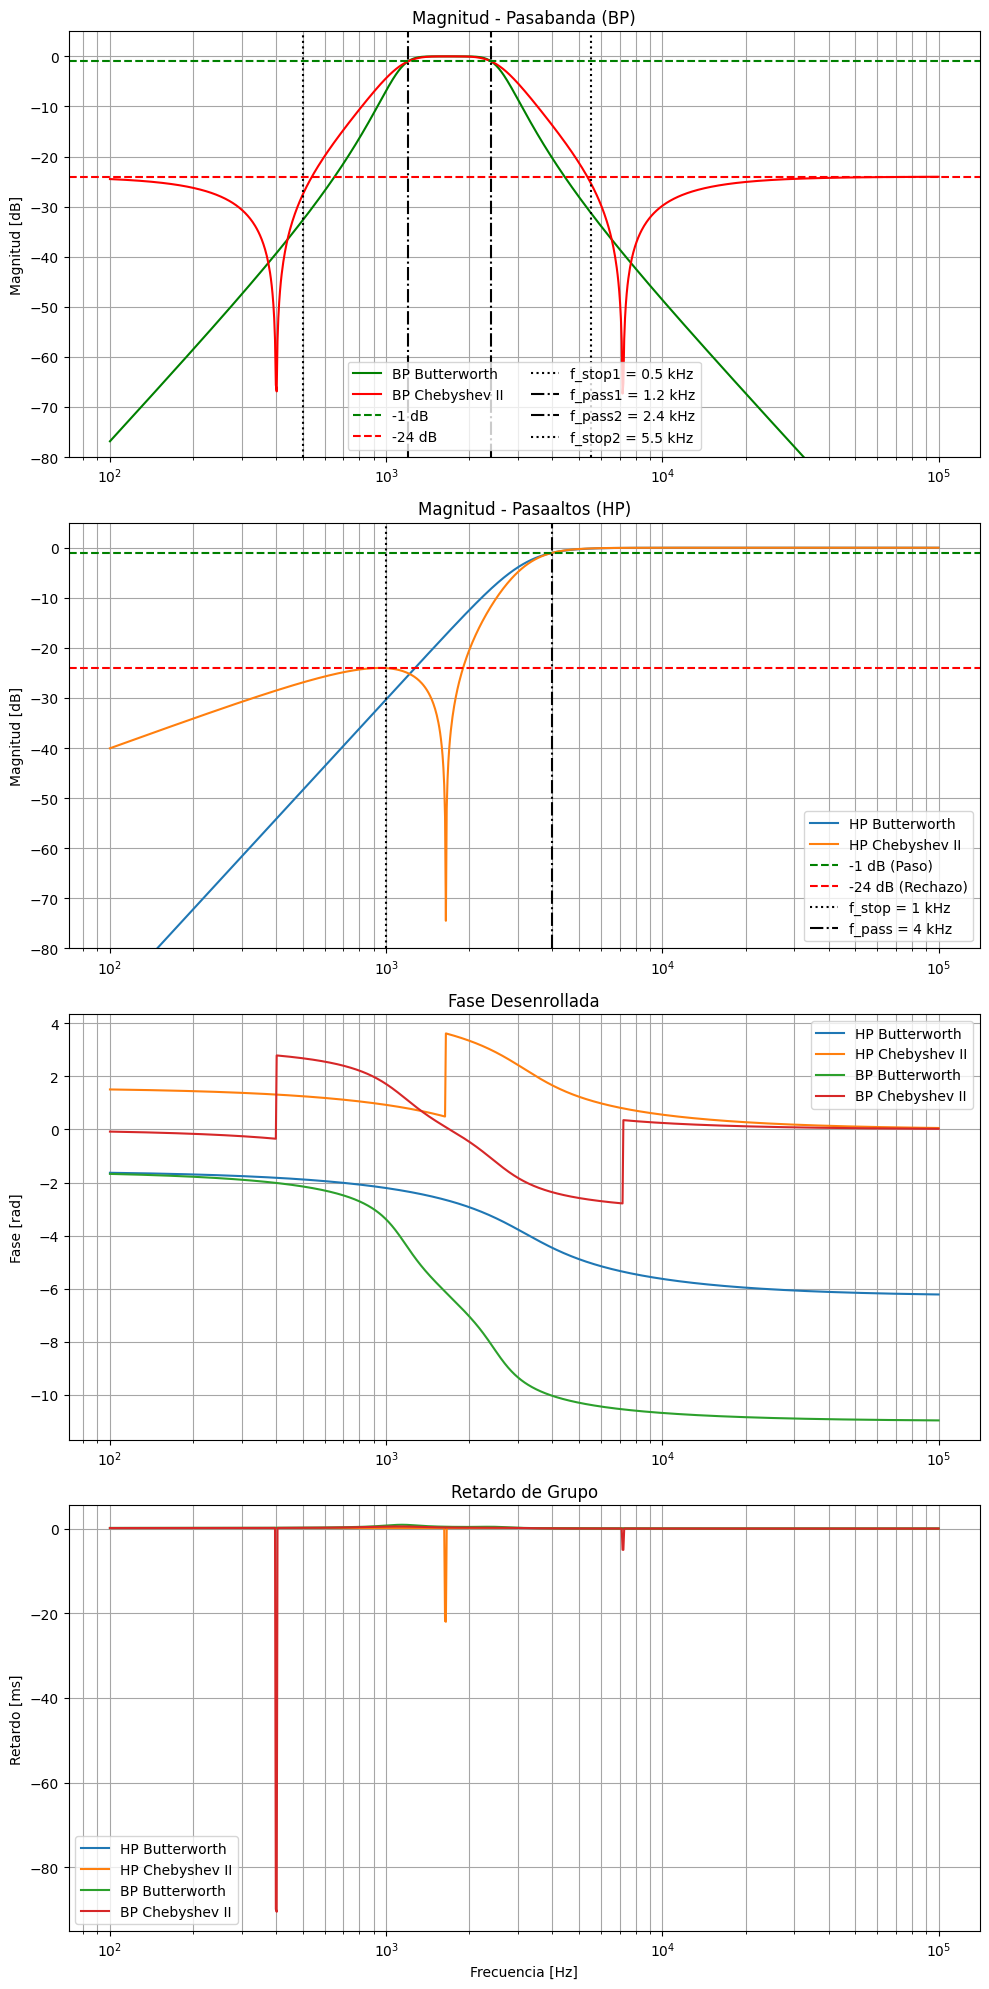

In [8]:
import numpy as np
import scipy.signal as sig
import matplotlib.pyplot as plt

# --- Especificaciones Generales ---
# Atenuación máxima en banda de paso y mínima en rechazo (en dB)[cite: 2]
Ap = 1.0
As = 24.0

# --- Especificaciones del Pasaaltos (HP) ---
# Frecuencias en Hz[cite: 2]
f_pass_hp = 4000
f_stop_hp = 1000

# Conversión a rad/s (w = 2*pi*f)[cite: 2]
w_pass_hp = 2 * np.pi * f_pass_hp
w_stop_hp = 2 * np.pi * f_stop_hp

# --- Especificaciones del Pasabanda (BP) ---
# Frecuencias en Hz[cite: 2]
f_pass_bp = [1200, 2400]
f_stop_bp = [500, 5500]

# Conversión a rad/s[cite: 2]
w_pass_bp = [2 * np.pi * f for f in f_pass_bp]
w_stop_bp = [2 * np.pi * f for f in f_stop_bp]

# ==========================================
# CÁLCULO DE FILTROS
# ==========================================

# 1. HP Butterworth
N_hp_butt, Wn_hp_butt = sig.buttord(w_pass_hp, w_stop_hp, Ap, As, analog=True)
z_hp_butt, p_hp_butt, k_hp_butt = sig.butter(N_hp_butt, Wn_hp_butt, btype='high', analog=True, output='zpk')

# 2. HP Chebyshev II
N_hp_cheb2, Wn_hp_cheb2 = sig.cheb2ord(w_pass_hp, w_stop_hp, Ap, As, analog=True)
z_hp_cheb2, p_hp_cheb2, k_hp_cheb2 = sig.cheby2(N_hp_cheb2, As, Wn_hp_cheb2, btype='highpass', analog=True, output='zpk')

# 3. BP Butterworth
N_bp_butt, Wn_bp_butt = sig.buttord(w_pass_bp, w_stop_bp, Ap, As, analog=True)
z_bp_butt, p_bp_butt, k_bp_butt = sig.butter(N_bp_butt, Wn_bp_butt, btype='bandpass', analog=True, output='zpk')

# 4. BP Chebyshev II
N_bp_cheb2, Wn_bp_cheb2 = sig.cheb2ord(w_pass_bp, w_stop_bp, Ap, As, analog=True)
z_bp_cheb2, p_bp_cheb2, k_bp_cheb2 = sig.cheby2(N_bp_cheb2, As, Wn_bp_cheb2, btype='bandpass', analog=True, output='zpk')


# ==========================================
# RESPUESTAS EN FRECUENCIA Y GRÁFICOS
# ==========================================
# Vector de frecuencias angulares en escala logarítmica[cite: 2]
w = np.logspace(np.log10(2*np.pi*100), np.log10(2*np.pi*100000), 1000)

_, H_hp_butt = sig.freqs_zpk(z_hp_butt, p_hp_butt, k_hp_butt, worN=w)
_, H_hp_cheb2 = sig.freqs_zpk(z_hp_cheb2, p_hp_cheb2, k_hp_cheb2, worN=w)
_, H_bp_butt = sig.freqs_zpk(z_bp_butt, p_bp_butt, k_bp_butt, worN=w)
_, H_bp_cheb2 = sig.freqs_zpk(z_bp_cheb2, p_bp_cheb2, k_bp_cheb2, worN=w)

# Crear figura con 4 subgráficos (BP, HP, Fase, Retardo)
fig, (ax_bp, ax_hp, ax_fase, ax_retardo) = plt.subplots(4, 1, figsize=(10, 20))

# 1. Magnitud - Pasabanda (BP)[cite: 2]
ax_bp.semilogx(w / (2*np.pi), 20 * np.log10(np.abs(H_bp_butt)), color='green', label='BP Butterworth')
ax_bp.semilogx(w / (2*np.pi), 20 * np.log10(np.abs(H_bp_cheb2)), color='red', label='BP Chebyshev II')
ax_bp.set_title('Magnitud - Pasabanda (BP)')
ax_bp.set_ylabel('Magnitud [dB]')
ax_bp.grid(True, which="both", ls="-", color='0.65')
ax_bp.axhline(-Ap, color='g', linestyle='--', label='-1 dB')
ax_bp.axhline(-As, color='r', linestyle='--', label='-24 dB')
ax_bp.axvline(500, color='black', linestyle=':', label='f_stop1 = 0.5 kHz')
ax_bp.axvline(1200, color='black', linestyle='-.', label='f_pass1 = 1.2 kHz')
ax_bp.axvline(2400, color='black', linestyle='-.', label='f_pass2 = 2.4 kHz')
ax_bp.axvline(5500, color='black', linestyle=':', label='f_stop2 = 5.5 kHz')
ax_bp.set_ylim(-80, 5)
ax_bp.legend(loc='lower center', ncol=2)

# 2. Magnitud - Pasaaltos (HP)[cite: 2]
ax_hp.semilogx(w / (2*np.pi), 20 * np.log10(np.abs(H_hp_butt)), label='HP Butterworth')
ax_hp.semilogx(w / (2*np.pi), 20 * np.log10(np.abs(H_hp_cheb2)), label='HP Chebyshev II')
ax_hp.set_title('Magnitud - Pasaaltos (HP)')
ax_hp.set_ylabel('Magnitud [dB]')
ax_hp.grid(True, which="both", ls="-", color='0.65')
ax_hp.axhline(-Ap, color='g', linestyle='--', label='-1 dB (Paso)')
ax_hp.axhline(-As, color='r', linestyle='--', label='-24 dB (Rechazo)')
ax_hp.axvline(1000, color='black', linestyle=':', label='f_stop = 1 kHz')
ax_hp.axvline(4000, color='black', linestyle='-.', label='f_pass = 4 kHz')
ax_hp.set_ylim(-80, 5)
ax_hp.legend()

# 3. Fase Desenrollada[cite: 2]
ax_fase.semilogx(w / (2*np.pi), np.unwrap(np.angle(H_hp_butt)), label='HP Butterworth')
ax_fase.semilogx(w / (2*np.pi), np.unwrap(np.angle(H_hp_cheb2)), label='HP Chebyshev II')
ax_fase.semilogx(w / (2*np.pi), np.unwrap(np.angle(H_bp_butt)), label='BP Butterworth')
ax_fase.semilogx(w / (2*np.pi), np.unwrap(np.angle(H_bp_cheb2)), label='BP Chebyshev II')
ax_fase.set_title('Fase Desenrollada')
ax_fase.set_ylabel('Fase [rad]')
ax_fase.grid(True, which="both", ls="-", color='0.65')
ax_fase.legend()

# 4. Retardo de Grupo[cite: 2]
ax_retardo.semilogx(w / (2*np.pi), -np.gradient(np.unwrap(np.angle(H_hp_butt)), w) * 1000, label='HP Butterworth')
ax_retardo.semilogx(w / (2*np.pi), -np.gradient(np.unwrap(np.angle(H_hp_cheb2)), w) * 1000, label='HP Chebyshev II')
ax_retardo.semilogx(w / (2*np.pi), -np.gradient(np.unwrap(np.angle(H_bp_butt)), w) * 1000, label='BP Butterworth')
ax_retardo.semilogx(w / (2*np.pi), -np.gradient(np.unwrap(np.angle(H_bp_cheb2)), w) * 1000, label='BP Chebyshev II')
ax_retardo.set_title('Retardo de Grupo')
ax_retardo.set_ylabel('Retardo [ms]')
ax_retardo.set_xlabel('Frecuencia [Hz]')
ax_retardo.grid(True, which="both", ls="-", color='0.65')
ax_retardo.legend()

plt.tight_layout()
plt.show()